# UNESCO World Heritage List — Exploratory Analysis

Dataset: `whc001.parquet` — 1,273 UNESCO World Heritage sites with names, descriptions (in 6 languages), inscription dates, category, region, area, criteria, danger status, coordinates, and more.

## Data source & attribution

- **Source:** [UNESCO DataHub — World Heritage List (`whc001`)](https://data.unesco.org/explore/assets/whc001/)
- **Publisher:** UNESCO
- **License:** CC BY-SA 4.0
- **Last modified (source):** 2026-09-19
- **Local snapshot used here:** `whc001.parquet`, 1,273 records, downloaded 2026-09-19

**Description:** This dataset lists UNESCO World Heritage sites recognized for outstanding cultural, natural, or mixed universal value. It includes site names and descriptions in six languages, inscription dates and criteria, danger-list status, area, geographic coordinates, the country/countries (states parties) responsible, and image/video metadata.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely import wkb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

## 1. Load the data

In [4]:
df = pd.read_parquet("datasets/whc001.parquet")
print(df.shape)
df.head()

(1273, 54)


,name_en,name_fr,name_es,name_ru,name_ar,name_zh,short_description_en,short_description_fr,short_description_es,short_description_ru,...,main_video_author,main_video_caption_en,main_video_caption_fr,main_video_caption_es,main_video_caption_ru,main_video_caption_ar,main_video_caption_zh,videos_urls,components_list,components_count
0,The Bony Fish Fossils of the Western Limfjord ...,Les fossiles de poissons osseux du Limfjord oc...,Los fósiles de peces óseos de Limfjord occiden...,Ископаемые остатки костистых рыб Западного Лим...,أحافير الأسماك العظمية في بحر ليمفيورد الغربي ...,利姆水道西段硬骨鱼化石——始新世最早期的演化和气候适应,"The serial property, located in the Western Li...","Le bien en série, situé dans la mer du Limfjor...","El bien, situado en el mar de Limfjord occiden...",Объект расположен в западной части Лим-фьорда ...,...,None,None,None,None,None,None,None,None,"{name: Hanklit, ref: 1758-001, latitude: 56.89...",2
1,Aalto Works,Les œuvres d’Aalto,Las obras de Aalto,Работы Аалто,أعمال آلتو,阿尔托作品,The property consists of thirteen modern build...,Le bien est composé de treize édifices et ense...,El bien se compone de trece edificios y conjun...,Объект включает тринадцать современных зданий ...,...,None,None,None,None,None,None,None,None,"{name: Villa Mairea, Pori, ref: 1752-013, lati...",13
2,"Beaches of the D-Day Landings, Normandy, 1944","Les Plages du Débarquement, Normandie, 1944","Las Playas del Desembarco, Normandía, 1944","Пляжи высадки в Нормандии, 1944 год",شواطئ إنزال الحلفاء في نورماندي عام 1944,1944年诺曼底登陆海滩,The serial property comprises six component pa...,Le bien en série est composé de six éléments c...,El bien está formado por seis emplazamientos a...,None,...,None,None,None,None,None,None,None,None,"{name: Gold Beach, ref: 1581-004, latitude: 49...",6
3,Ancient Buddhist Site of Sarnath,Site bouddhiste ancien de Sarnath,Antiguo sitio budista de Sarnath,Древний буддийский комплекс Сарнатх,موقع سارناث البوذي القديم,鹿野苑古佛教遗址,The serial property contains the architectural...,Le bien en série comprend les vestiges archite...,El bien está formado por un conjunto de restos...,Серийный объект охватывает архитектурные и арх...,...,None,None,None,None,None,None,None,None,"{name: Chaukandi Stupa, ref: 927-001, latitude...",2
4,Alamūt Castle and Related Fortifications,Château d’Alamūt et fortifications associées,Castillo de Alamūt y fortificaciones relacionadas,Замок Аламут и связанные укрепления,قلعة ألَموت والحصون التابعة لها,阿拉穆特城堡及相关防御工事,The serial property consists of Alamūt Castle ...,Le bien en série comprend la forteresse d’Alam...,El bien es un conjunto formado por el castillo...,Серийный объект включает замок Аламут и шесть ...,...,None,None,None,None,None,None,None,None,"{name: Alamūt Castle, ref: 1770-001, latitude:...",7


## 2. Select useable columns for analysis

The raw dataset has 54 columns, many of which are per-language captions/descriptions or video metadata not needed here. Keep only the analysis-relevant columns (`id_no` = ID, `name_en` = Name EN).

In [5]:
USEABLE_COLUMNS = [
    "id_no",  # ID
    "category_id",
    "category",
    "name_en",  # Name EN
    "short_description_en",
    "description_en",
    "justification_en",
    "date_inscribed",
    "secondary_dates",
    "danger",
    "danger_list",
    "area_hectares",
    "states_names",
    "iso_codes",
    "region",
    "region_code",
    "transboundary",
    "main_image_url",
    "main_image_author",
    "main_image_copyright",
    "main_image_caption_en",
    "images_urls",
    "coordinates",
    "components_list",
    "components_count",
]

df = df[USEABLE_COLUMNS].rename(columns={"states_names": "country","date_inscribed": "year_inscribed"})
print(df.shape)
df.head()

(1273, 25)


,id_no,category_id,category,name_en,short_description_en,description_en,justification_en,year_inscribed,secondary_dates,danger,...,region_code,transboundary,main_image_url,main_image_author,main_image_copyright,main_image_caption_en,images_urls,coordinates,components_list,components_count
0,1758,2,Natural,The Bony Fish Fossils of the Western Limfjord ...,"The serial property, located in the Western Li...","The serial property, located in the Western Li...",None,2026-01-01,2026,False,...,EUR,False,https://whc.unesco.org/document/220972,Museum Mors,Museum Mors,The extremely wellpreserved marine turtle Tasb...,"https://whc.unesco.org/document/220968, https:...",None,"{name: Hanklit, ref: 1758-001, latitude: 56.89...",2
1,1752,1,Cultural,Aalto Works,The property consists of thirteen modern build...,The property consists of thirteen modern build...,None,2026-01-01,2026,False,...,EUR,False,https://whc.unesco.org/document/220328,Maija Holma,Alvar Aalto Foundation,Interior view through the Aalto house: the din...,"https://whc.unesco.org/document/220323, https:...",None,"{name: Villa Mairea, Pori, ref: 1752-013, lati...",13
2,1581,1,Cultural,"Beaches of the D-Day Landings, Normandy, 1944",The serial property comprises six component pa...,The serial property comprises six component pa...,None,2026-01-01,2026,False,...,EUR,False,https://whc.unesco.org/document/225330,Michel Dehaye,Michel Dehaye,Mulberry B and the cliffs of Tracy-sur-Mer,"https://whc.unesco.org/document/225330, https:...",None,"{name: Gold Beach, ref: 1581-004, latitude: 49...",6
3,927,1,Cultural,Ancient Buddhist Site of Sarnath,The serial property contains the architectural...,The serial property contains the architectural...,None,2026-01-01,2026,False,...,APA,False,https://whc.unesco.org/document/220772,Archaeological Survey of India,Archaeological Survey of India,Lion Capital of the Ashokan Pillar during exca...,"https://whc.unesco.org/document/220772, https:...",None,"{name: Chaukandi Stupa, ref: 927-001, latitude...",2
4,1770,1,Cultural,Alamūt Castle and Related Fortifications,The serial property consists of Alamūt Castle ...,The serial property consists of Alamūt Castle ...,None,2026-01-01,2026,False,...,APA,False,https://whc.unesco.org/document/220796,Mohammad Mahmoudi,ACHB,Alamūt Castle,"https://whc.unesco.org/document/220795, https:...",None,"{name: Alamūt Castle, ref: 1770-001, latitude:...",7


## 3. Extract year from `year_inscribed`

Keep only the year of inscription (else null).

In [6]:
df["year_inscribed"] = pd.to_datetime(df["year_inscribed"], errors="coerce").dt.year

is_valid_year = df["year_inscribed"].notna() & df["year_inscribed"].between(1000, 9999)
before = len(df)
df = df[is_valid_year].copy()
after = len(df)
print(f"Dropped {before - after} row(s) without a valid year_inscribed; {after} remain")

df["year_inscribed"] = df["year_inscribed"].astype(int)
df["year_inscribed"].head()

Dropped 0 row(s) without a valid year_inscribed; 1273 remain


0    2026
1    2026
2    2026
3    2026
4    2026
Name: year_inscribed, dtype: int32

## 4. Validate `danger`

Keep only records where `danger` is exactly `True` or `False`; drop anything else.

In [7]:
before = len(df)
df = df[df["danger"].isin(["True", "False"])].copy()
after = len(df)
print(f"Dropped {before - after} row(s) with an invalid danger value; {after} remain")

df["danger"].value_counts()

Dropped 0 row(s) with an invalid danger value; 1273 remain


False    1215
True       58
Name: danger, dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1273 entries, 0 to 1272
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_no                  1273 non-null   object 
 1   category_id            1273 non-null   int64  
 2   category               1273 non-null   object 
 3   name_en                1273 non-null   object 
 4   short_description_en   1272 non-null   object 
 5   description_en         1272 non-null   object 
 6   justification_en       1195 non-null   object 
 7   year_inscribed         1273 non-null   int32  
 8   secondary_dates        1273 non-null   object 
 9   danger                 1273 non-null   object 
 10  danger_list            58 non-null     object 
 11  area_hectares          1252 non-null   float64
 12  country                1273 non-null   object 
 13  iso_codes              1272 non-null   object 
 14  region                 1273 non-null   object 
 15  regi

## 5. Missing values

Many columns are per-language captions/descriptions, so sparsity is expected for some languages.

In [9]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0].head(20)

danger_list              95.443833
justification_en          6.127258
main_image_author         6.048704
main_image_copyright      4.477612
coordinates               2.278083
area_hectares             1.649647
images_urls               0.942655
main_image_caption_en     0.942655
main_image_url            0.942655
components_list           0.157109
short_description_en      0.078555
description_en            0.078555
iso_codes                 0.078555
dtype: float64

## 6. Category & region breakdown

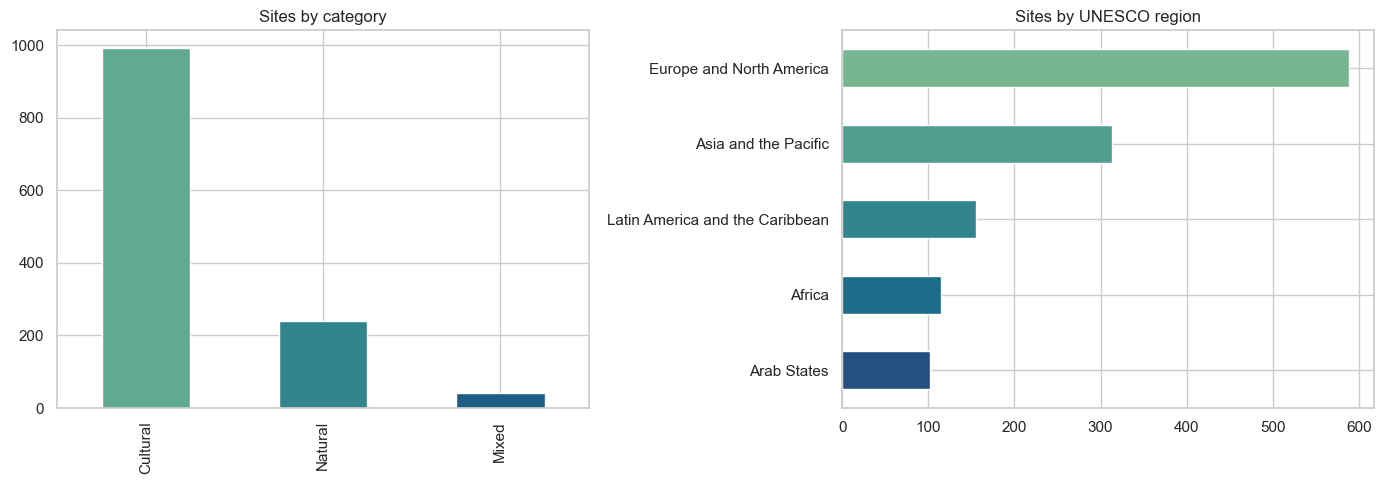

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["category"].value_counts().plot(kind="bar", ax=axes[0], color=sns.color_palette("crest", 3))
axes[0].set_title("Sites by category")
axes[0].set_xlabel("")

df["region"].value_counts().plot(kind="barh", ax=axes[1], color=sns.color_palette("crest", 5))
axes[1].set_title("Sites by UNESCO region")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## 7. Sites in danger

In [11]:
danger_counts = df["danger"].value_counts()
print(danger_counts)
print(f"\n{danger_counts.get('True', 0)} of {len(df)} sites ({danger_counts.get('True', 0) / len(df):.1%}) are currently on the danger list")

df.loc[df["danger"] == "True", ["name_en", "country", "region", "category"]]

False    1215
True       58
Name: danger, dtype: int64

58 of 1273 sites (4.6%) are currently on the danger list


,name_en,country,region,category
5,Mount Amel Castles,Lebanon,Arab States,Cultural
8,Sebastia,State of Palestine,Arab States,Cultural
14,Boma–Badingilo Migratory Landscape,South Sudan,Africa,Natural
64,Saint Hilarion Monastery/ Tell Umm Amer,State of Palestine,Arab States,Cultural
88,The Historic Centre of Odesa,Ukraine,Europe and North America,Cultural
110,Rachid Karami International Fair-Tripoli,Lebanon,Arab States,Cultural
119,"Landmarks of the Ancient Kingdom of Saba, Marib",Yemen,Arab States,Cultural
128,Roșia Montană Mining Landscape,Romania,Europe and North America,Cultural
206,Hebron/Al-Khalil Old Town,State of Palestine,Arab States,Cultural
242,Nan Madol: Ceremonial Centre of Eastern Micron...,Micronesia (Federated States of),Asia and the Pacific,Cultural


## 8. Inscriptions over time

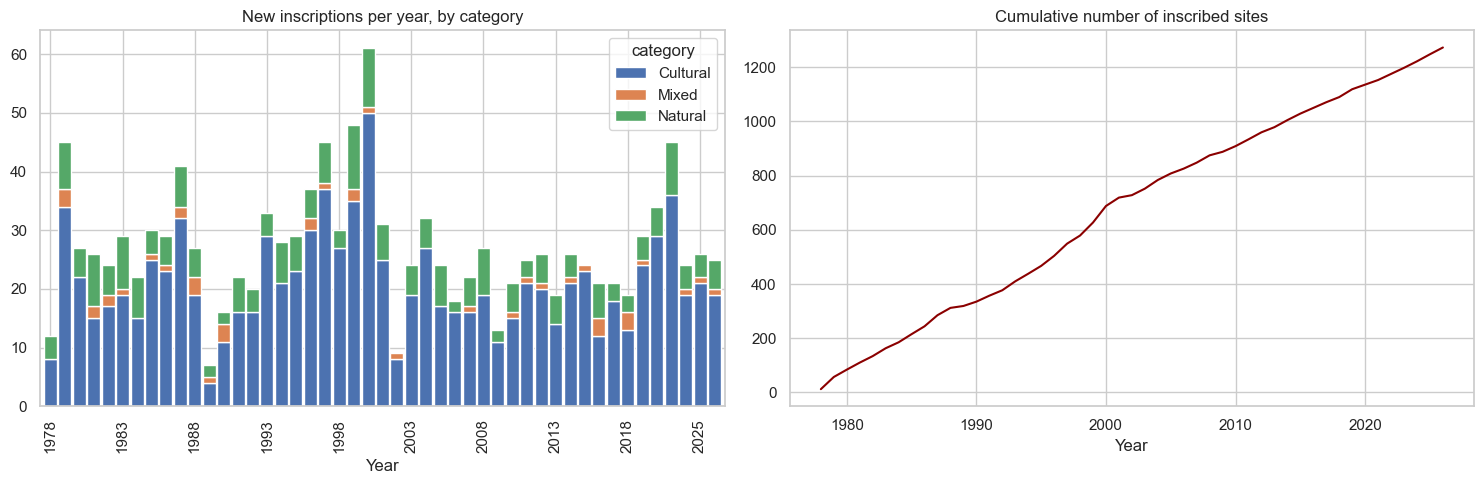

In [12]:
by_year_cat = df.groupby(["year_inscribed", "category"]).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

by_year_cat.plot(kind="bar", stacked=True, ax=axes[0], width=0.9)
axes[0].set_title("New inscriptions per year, by category")
axes[0].set_xlabel("Year")
axes[0].xaxis.set_major_locator(plt.MultipleLocator(5))

by_year_cat.sum(axis=1).cumsum().plot(ax=axes[1], color="darkred")
axes[1].set_title("Cumulative number of inscribed sites")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()

## 9. Geographic distribution

`coordinates` is stored as WKB (well-known binary) point geometry — decode it with `shapely` to get lat/lon.

In [13]:
def decode_point(geom):
    if geom is None:
        return pd.Series({"lat": np.nan, "lon": np.nan})
    p = wkb.loads(geom)
    return pd.Series({"lat": p.y, "lon": p.x})

df[["lat", "lon"]] = df["coordinates"].apply(decode_point)
print(f"{df['lat'].notna().sum()} of {len(df)} sites have coordinates")
df[["lat", "lon"]].describe()

1244 of 1273 sites have coordinates


,lat,lon
count,1244.000000,1244.000000
mean,28.863597,21.479008
std,23.595204,62.599688
min,-54.594722,-179.715278
25%,17.056601,-3.003792
50%,35.885075,17.459931
75%,45.675836,51.457996
max,71.188889,178.834533


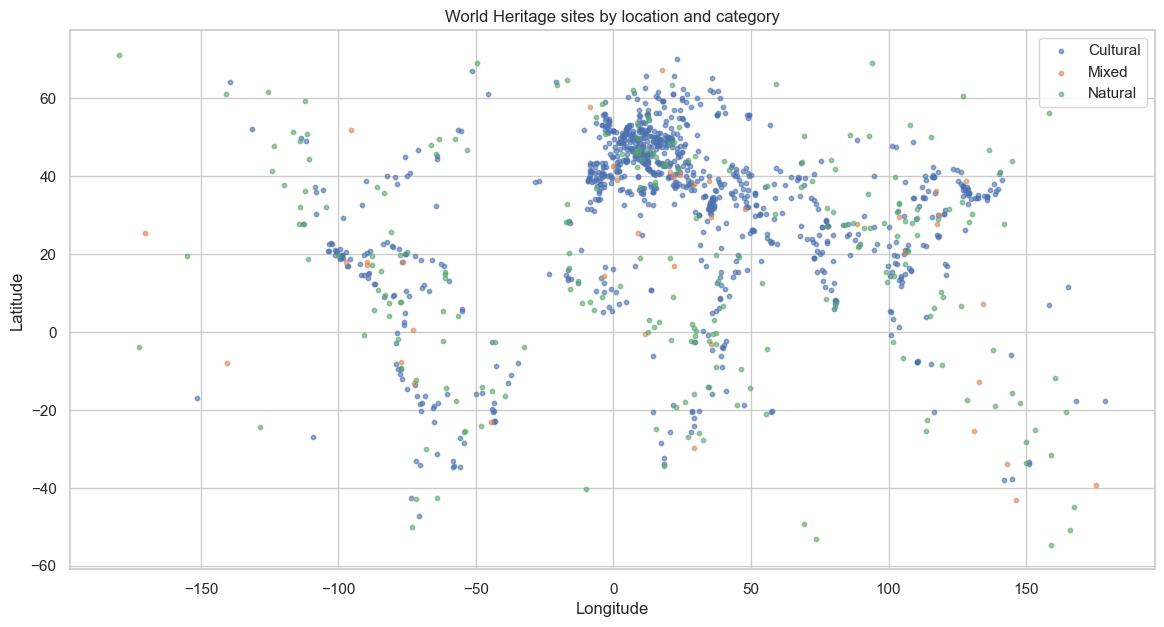

In [14]:
fig, ax = plt.subplots(figsize=(14, 7))
for cat, sub in df.dropna(subset=["lat", "lon"]).groupby("category"):
    ax.scatter(sub["lon"], sub["lat"], s=10, alpha=0.6, label=cat)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("World Heritage sites by location and category")
ax.legend()
plt.show()

## 10. Site area

`area_hectares` is heavily right-skewed (a few huge natural sites dominate), so plot on a log scale.

In [15]:
df["area_hectares"].describe()

count    1.252000e+03
mean     3.943826e+05
std      5.102469e+06
min      0.000000e+00
25%      2.233500e+01
50%      2.503500e+02
75%      1.443969e+04
max      1.662671e+08
Name: area_hectares, dtype: float64

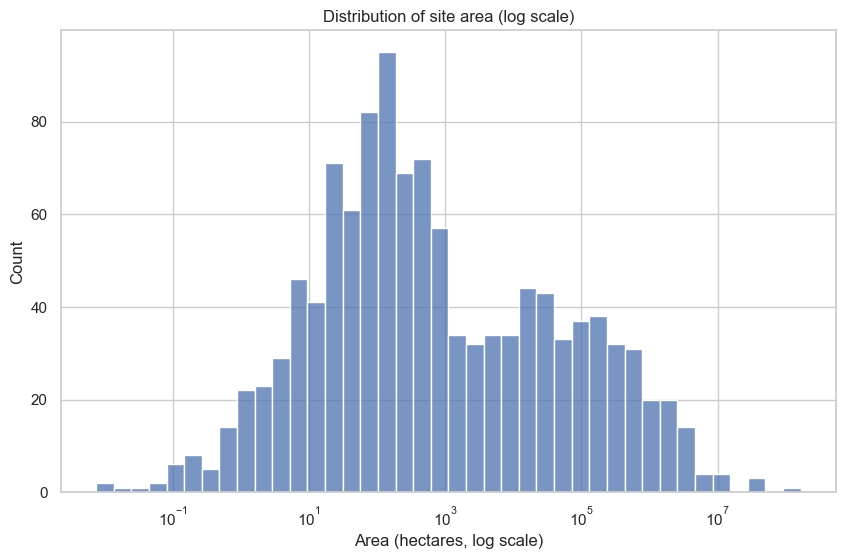

,name_en,area_hectares,country,category
175,French Austral Lands and Seas,166267100.0,France,Natural
365,Phoenix Islands Protected Area,40825000.0,Kiribati,Natural
368,Papahānaumokuākea,36207499.0,United States of America,Mixed
1168,Great Barrier Reef,34870000.0,Australia,Natural
1261,Galápagos Islands,14066514.0,Ecuador,Natural
14,Boma–Badingilo Migratory Landscape,11236800.0,South Sudan,Natural
1218,Kluane / Wrangell-St. Elias / Glacier Bay / Ta...,9839121.0,"Canada,United States of America",Natural
775,Lake Baikal,8800000.0,Russian Federation,Natural
934,Air and Ténéré Natural Reserves,7736000.0,Niger,Natural
1140,Tassili n'Ajjer,7200000.0,Algeria,Mixed


In [16]:
fig, ax = plt.subplots()
sns.histplot(df.loc[df["area_hectares"] > 0, "area_hectares"], log_scale=True, bins=40, ax=ax)
ax.set_title("Distribution of site area (log scale)")
ax.set_xlabel("Area (hectares, log scale)")
plt.show()

df.nlargest(10, "area_hectares")[["name_en", "area_hectares", "country", "category"]]

## 11. Top countries by number of sites

Transboundary sites list multiple states in `country` (comma-separated), so explode before counting.

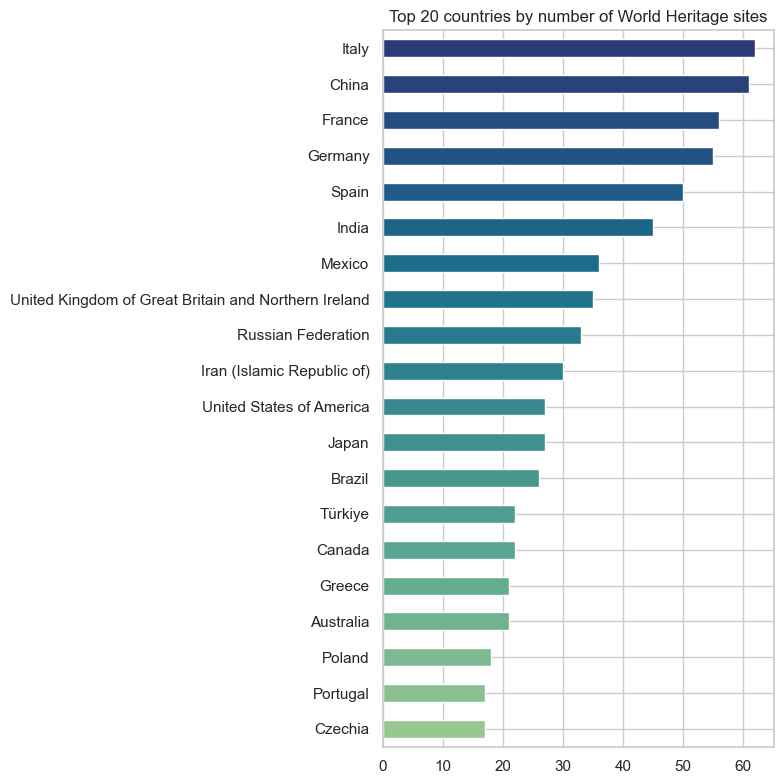

In [17]:
country_counts = (
    df["country"].str.split(",").explode().str.strip().value_counts().head(20)
)

fig, ax = plt.subplots(figsize=(8, 8))
country_counts.sort_values().plot(kind="barh", ax=ax, color=sns.color_palette("crest", 20))
ax.set_title("Top 20 countries by number of World Heritage sites")
plt.tight_layout()
plt.show()

## 12. Transboundary sites

In [18]:
print(df["transboundary"].value_counts())
df.loc[df["transboundary"] == "True", ["name_en", "country", "region"]]

False    1222
True       51
Name: transboundary, dtype: int64


,name_en,country,region
75,Funerary and memory sites of the First World W...,"France,Belgium",Europe and North America
86,Silk Roads: Zarafshan-Karakum Corridor,"Tajikistan,Uzbekistan,Turkmenistan",Asia and the Pacific
99,Cold Winter Deserts of Turan,"Kazakhstan,Uzbekistan,Turkmenistan",Asia and the Pacific
120,Frontiers of the Roman Empire – The Danube Lim...,"Austria,Slovakia,Germany",Europe and North America
139,The Great Spa Towns of Europe,"Italy,France,Austria,Belgium,United Kingdom of...",Europe and North America
140,Colonies of Benevolence,"Belgium,Netherlands (Kingdom of the)",Europe and North America
142,Frontiers of the Roman Empire – The Lower Germ...,"Netherlands (Kingdom of the),Germany",Europe and North America
155,Hyrcanian Forests,"Azerbaijan,Iran (Islamic Republic of)",Europe and North America
173,Erzgebirge/Krušnohoří Mining Region,"Germany,Czechia",Europe and North America
203,Venetian Works of Defence between the 16th and...,"Italy,Croatia,Montenegro",Europe and North America


## Next steps

Ideas to extend this analysis:
- Plot sites on an actual world basemap with `geopandas`/`contextily` instead of a raw scatter.
- Compare danger-listed sites by region/category to see where risk concentrates.
- Text-mine `description_en` / `justification_en` for common themes per category.
- Join `iso_codes` against an external dataset (population, GDP, land area) to normalize site counts per country.

## 13. Export cleaned data to CSV

Save the cleaned, column-filtered dataset (including the derived `year_inscribed`, `lat`, `lon` columns) to CSV for use outside this notebook.

In [19]:
output_path = "datasets/whc001_cleaned.csv"
df = df.drop(columns='coordinates')
df.to_csv(output_path, index=False)
print(f"Saved {len(df)} rows x {df.shape[1]} columns to {output_path}")

Saved 1273 rows x 26 columns to datasets/whc001_cleaned.csv
